# Lattice-first：一步步看懂演算法

**目標**：給一張 Reference（3×3 個 Unit Cell）與一張大 FoV 的 Search Image，框出所有與 Reference 同 Phase、彼此不重疊的 Instance，並標記 Anomalous Instance。

Template Matching 是「把 Reference 在每個位置、每個尺度/角度都比一次，再用閾值 + NMS 挑框」。
Lattice-first 反過來利用**週期性**：

| 步驟 | 做什麼 | 對應函式（`periodic_match.lattice`） |
|---|---|---|
| 1 | Reference 的 Fourier 係數 $C_h$：它「長什麼樣」與「Phase 在哪」都在裡面 | `ref_coefficients`, `pick_harmonics` |
| 2 | 幾何：在 Search Image 的功率譜上找尺度 $s$、角度 $\theta$ | `geometry_objective`, `fit_geometry` |
| 3 | GPA：兩個基本諧波的局部相位圖 | `make_frame`, `_gpa` |
| 4 | Periodic Region：晶格自相似度 | `periodic_regions` |
| 5 | 晶格節點：Newton 迭代讓相位對齊 Reference | `newton_nodes` |
| 6 | 由中心往外擬合 affine，壞節點用鄰近漂移補 | `solve_nodes` |
| 7 | 極性 / 諧波符號假設（對比反轉、強 gamma） | `templates`, `score_hypotheses` |
| 8 | Instance Grid：每塊 Periodic Region 取 Instance 最多的切法 | `instance_grid`, `finalize` |
| 9 | Anomalous Instance：9 個 Cell ZNCC 的最小值 | `finalize` |

**怎麼用**：改下面「參數」那格，然後 *Run All*。每一步最後都有「試試看」。
`LatticeMatcher().analyze()` 就是依序呼叫這些函式；最後一節會驗證兩者結果完全相同。

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.colors import ListedColormap

from periodic_match import lattice as L
from periodic_match.synth import Design, Imaging, make_scene
from periodic_match.metrics import detection_pr, match_instances

plt.rcParams.update({"font.family": ["Heiti TC", "Arial Unicode MS", "DejaVu Sans"], "figure.dpi": 100,
                     "axes.titlesize": 10, "image.interpolation": "nearest"})
GREEN, RED, BLUE, ORANGE = "#1baf7a", "#e34948", "#2a78d6", "#eb6834"

## 0. 參數與合成場景

合成的 SEM 風格 contact hole array（孔內暗、孔緣亮）。Search Image 有兩塊非 Periodic Region（不同 pitch 的干擾孔陣、隨機繞線），Reference 以另一組灰階條件渲染，模擬不同機台。

In [2]:
LATTICE = "square"          # "square" | "hex"
PITCH = 48                  # Reference 上的孔距（px）
HOLE_OFFSET = (0.3, 0.6)    # 孔在 Unit Cell 內的位置（比例）→ 決定 Reference 的 Phase
IMAGING = Imaging(
    scale=1.12, rotation_deg=3.1,   # 相對 Reference 的倍率與旋轉
    elastic=0.05,                   # 局部形變（pitch 比例）
    gamma=1.4, contrast=0.85, gradient=0.15,
    noise=0.06, defect_rate=0.03,
    invert=False,                   # 對比反轉
    occlusion=0.0,                  # 微粒遮擋面積比例
)
REF_IMAGING = Imaging(gamma=0.85, noise=0.02)
SEED = 7

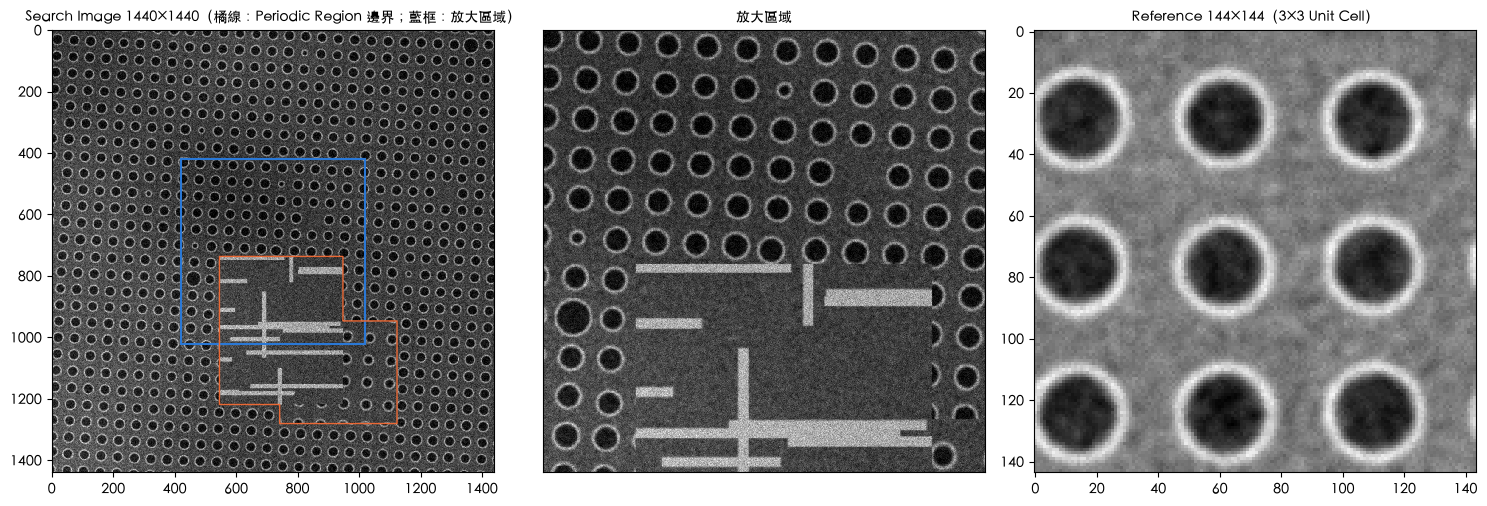

真值：scale=1.12, rotation=3.1°；合法 Instance 最多 47 個


In [3]:
scene = make_scene(Design(LATTICE, PITCH, HOLE_OFFSET), IMAGING, REF_IMAGING, seed=SEED)
search, ref = scene.search, scene.reference
H, W = search.shape
c0 = min(H, W) // 2 - 300                      # 後面各步驟共用的放大區域
CROP = (slice(c0, c0 + 600), slice(c0, c0 + 600))

def show_crop(ax, img=None, **kw):
    ax.imshow(search[CROP] if img is None else img[CROP], cmap=kw.pop("cmap", "gray"), **kw)
    ax.set_xticks([]); ax.set_yticks([])

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(search, cmap="gray"); ax[0].contour(scene.periodic_mask, [0.5], colors=ORANGE, linewidths=1)
ax[0].add_patch(plt.Rectangle((c0, c0), 600, 600, fill=False, ec=BLUE, lw=1.5))
ax[0].set_title(f"Search Image {W}×{H}（橘線：Periodic Region 邊界；藍框：放大區域）")
show_crop(ax[1]); ax[1].set_title("放大區域")
ax[2].imshow(ref, cmap="gray"); ax[2].set_title(f"Reference {ref.shape[1]}×{ref.shape[0]}（3×3 Unit Cell）")
plt.tight_layout(); plt.show()
print(f"真值：scale={IMAGING.scale}, rotation={IMAGING.rotation_deg}°；合法 Instance 最多 {scene.n_max} 個")

## 1. Reference 的 Fourier 係數

Reference 剛好是 3×3 個 Unit Cell，所以它是一個週期函數的一小片。以 Reference **中心**為原點、Unit Cell 為單位的座標 $q$，可以寫成

$$R(q) \approx \sum_h C_h\, e^{2\pi i\, h\cdot q},\qquad h=(m,n)\ \text{為整數}$$

- $|C_h|$：結構「長什麼樣」（孔的大小、邊緣亮暗）
- $\arg C_h$：結構相對 Reference 中心的**位置**——也就是 Phase

挑兩個最低階、不共線、振幅夠大的諧波 $h_1, h_2$ 來定位節點。方形陣列是 (1,0)、(0,1)；六角陣列的 (1,0) 因對稱性消失，會選 (1,1)、(1,−1)。

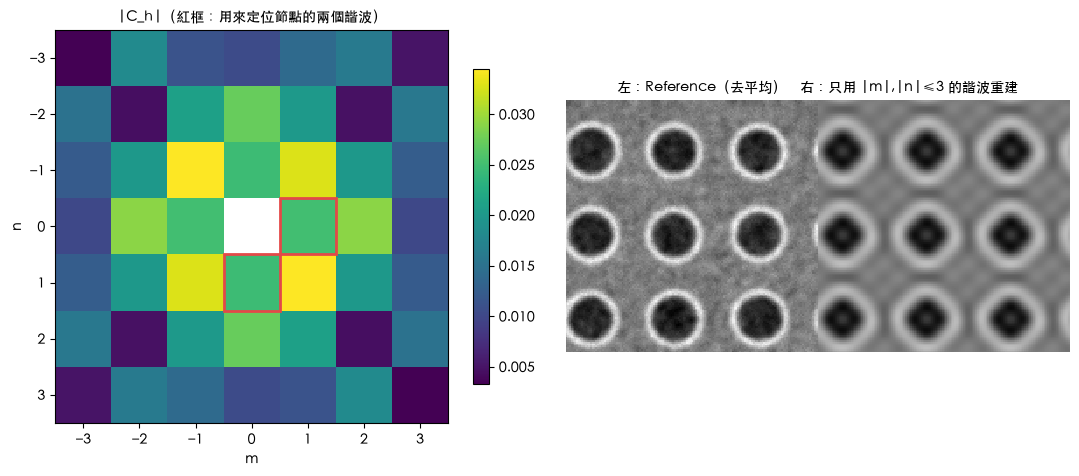

節點諧波 h1, h2 = ((1, 0), (0, 1)) ；相位 arg C = ['-1.87', '+2.53']


In [4]:
cell = (ref.shape[1] / 3, ref.shape[0] / 3)
C, ref_rms = L.ref_coefficients(ref, cell)
hs = L.pick_harmonics(C)

K = 3
amp = np.zeros((2 * K + 1, 2 * K + 1))
for (m, n), v in C.items():           # C 只存半平面；實數影像 C_{-h} = conj(C_h)
    amp[n + K, m + K] = amp[-n + K, -m + K] = abs(v)
amp[K, K] = np.nan

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
im = ax[0].imshow(amp, cmap="viridis", extent=(-K - .5, K + .5, K + .5, -K - .5))
for h in hs:
    ax[0].add_patch(plt.Rectangle((h[0] - .5, h[1] - .5), 1, 1, fill=False, ec=RED, lw=2))
ax[0].set_xlabel("m"); ax[0].set_ylabel("n"); ax[0].set_title("|C_h|（紅框：用來定位節點的兩個諧波）")
plt.colorbar(im, ax=ax[0], shrink=0.8)

# 只用 |h|≤3 的諧波重建 Reference：看看這些係數涵蓋了多少資訊
hh, ww = ref.shape
y, x = np.mgrid[0:hh, 0:ww]
qx, qy = (x - (ww - 1) / 2) / cell[0], (y - (hh - 1) / 2) / cell[1]
rec = sum(2 * (v * np.exp(2j * np.pi * (k[0] * qx + k[1] * qy))).real for k, v in C.items())
ax[1].imshow(np.hstack([ref - ref.mean(), rec]), cmap="gray")
ax[1].set_title("左：Reference（去平均）　右：只用 |m|,|n|≤3 的諧波重建"); ax[1].axis("off")
plt.tight_layout(); plt.show()
print("節點諧波 h1, h2 =", hs, "；相位 arg C =", [f"{np.angle(C[h]):+.2f}" for h in hs])

**試試看**：把 `LATTICE` 改成 `"hex"`，看 (1,0)、(0,1) 的振幅變成 0、選到的諧波換成 (1,±1)。把 `HOLE_OFFSET` 改掉，$|C_h|$ 幾乎不變，但 $\arg C_h$ 會跟著變——Phase 就藏在相位裡。

## 2. 幾何：功率譜上找尺度與角度

Search Image 的晶格向量 $= s\,R(\theta)\,(\text{Reference 的 Cell 向量})$，所以它的功率譜峰值落在

$$g_h = R(\theta)\,\big(m/c_w,\ n/c_h\big)/s \quad(\text{cycles/px})$$

對每組 $(s,\theta)$，把 Reference 的 $|C_h|$ 當權重、取樣對數功率譜在 $g_h$ 的值加總，最大者就是答案（先格點搜尋，再 Nelder-Mead 精修）。

**為什麼 robust**：功率譜 $|F|^2$ 不含相位 → 不受平移影響；對比反轉只改變號 → $|F|^2$ 不變；灰階非線性只改變各諧波的相對強弱，峰值**位置**不變。也不用像 Template Matching 那樣窮舉 11 個尺度 × 5 個角度去比對。

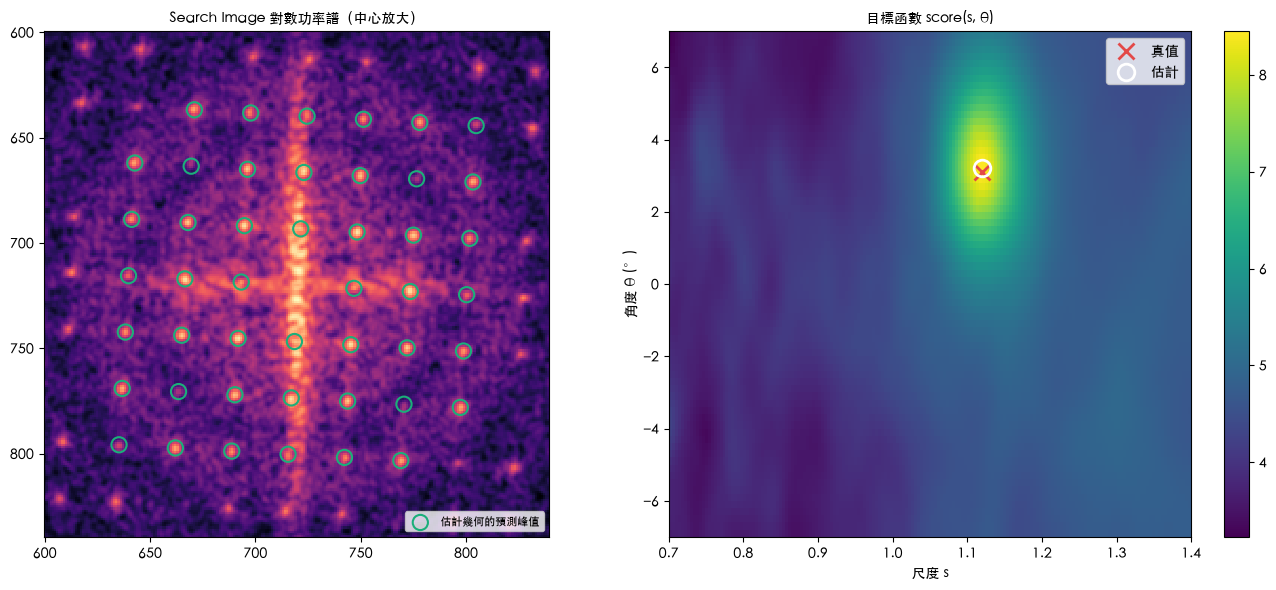

估計 s=1.1197（真值 1.12），θ=+3.21°（真值 +3.1°）


In [5]:
hp = L.highpass(search, cell)                  # 去掉低頻亮度漂移
P, score = L.geometry_objective(hp, C, cell)
s, th = L.fit_geometry(hp, C, cell)

S, T = np.meshgrid(np.arange(0.7, 1.4, 0.004), np.deg2rad(np.arange(-7, 7, 0.2)))
landscape = score(S, T)

def peaks(s, th):
    pts = []
    for (m, n), v in C.items():
        if abs(v) < 0.1 * max(abs(u) for u in C.values()):
            continue
        kx, ky = m / cell[0], n / cell[1]
        gx = (np.cos(th) * kx - np.sin(th) * ky) / s
        gy = (np.sin(th) * kx + np.cos(th) * ky) / s
        pts += [(W // 2 + gx * W, H // 2 + gy * H), (W // 2 - gx * W, H // 2 - gy * H)]
    return np.array(pts)

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
r = int(4.5 * W / (s * min(cell)))
ax[0].imshow(P[H // 2 - r:H // 2 + r, W // 2 - r:W // 2 + r], cmap="magma",
             extent=(W // 2 - r - .5, W // 2 + r - .5, H // 2 + r - .5, H // 2 - r - .5))
pk = peaks(s, th)
ax[0].scatter(pk[:, 0], pk[:, 1], s=120, facecolors="none", edgecolors=GREEN, lw=1.5, label="估計幾何的預測峰值")
ax[0].legend(loc="lower right", fontsize=8); ax[0].set_title("Search Image 對數功率譜（中心放大）")
im = ax[1].imshow(landscape, aspect="auto", cmap="viridis", origin="lower",
                  extent=(0.7, 1.4, -7, 7))
ax[1].plot(IMAGING.scale, IMAGING.rotation_deg, "x", color=RED, ms=12, mew=2, label="真值")
ax[1].plot(s, np.rad2deg(th), "o", mfc="none", color="white", ms=12, mew=2, label="估計")
ax[1].set_xlabel("尺度 s"); ax[1].set_ylabel("角度 θ (°)"); ax[1].legend(); ax[1].set_title("目標函數 score(s, θ)")
plt.colorbar(im, ax=ax[1]); plt.tight_layout(); plt.show()
print(f"估計 s={s:.4f}（真值 {IMAGING.scale}），θ={np.rad2deg(th):+.2f}°（真值 {IMAGING.rotation_deg:+}°）")

**試試看**：設 `invert=True` 或 `gamma=3.5`，功率譜幾乎一樣，估計值也不變。景觀圖裡的其他亮點來自干擾孔陣（pitch ×1.35）或諧波混疊；面積較小，所以贏不了主晶格。

## 3. GPA：局部相位圖

有了 $(s,\theta)$ 就有全域的 $q = Bx$。實際的 $q(x) = Bx + \delta(x)$，$\delta$ 是緩慢變化的局部漂移（形變、平移）。GPA（geometric phase analysis）把影像乘上 $e^{-2\pi i\,g_k\cdot x}$ 再低通（σ = 1 Cell）：

$$H_k(x) = G_\sigma * \big(I(x)\,e^{-2\pi i\, g_k\cdot x}\big) \approx C_k\, e^{2\pi i\, h_k\cdot\delta(x)}$$

所以 $\arg H_k$ 直接給出局部漂移 $h_k\cdot\delta(x)$：在 Periodic Region 裡是平滑的，在非週期區是雜亂的。

g_k (cycles/px) =
 [[ 0.01858  0.00104]
 [-0.00104  0.01858]]


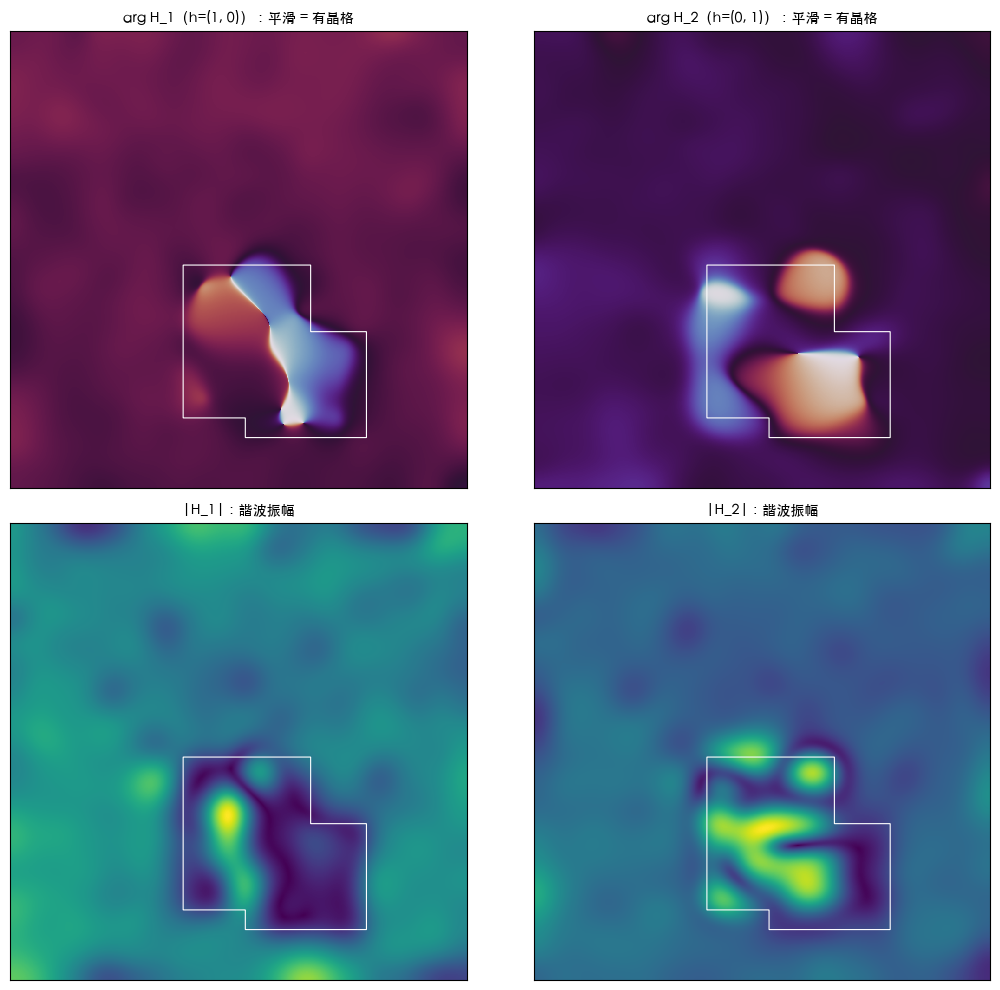

In [6]:
fr = L.make_frame(cell, s, th, C)
sigma = fr.cell_s                              # GPA 低通 σ = 1 個 Cell
gpa = [L._gpa(hp, fr.G[k], sigma) for k in range(2)]
print("g_k (cycles/px) =\n", fr.G.round(5))

fig, ax = plt.subplots(2, 2, figsize=(11, 10))
for k, (re, im) in enumerate(gpa):
    ax[0, k].imshow(np.angle(re + 1j * im), cmap="twilight"); ax[0, k].set_title(f"arg H_{k + 1}（h={fr.hs[k]}）：平滑 = 有晶格")
    ax[1, k].imshow(np.hypot(re, im), cmap="viridis"); ax[1, k].set_title(f"|H_{k + 1}|：諧波振幅")
for a in ax.flat:
    a.contour(scene.periodic_mask, [0.5], colors="white", linewidths=0.8); a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

**試試看**：把 `elastic` 調到 0.15，相位圖會出現明顯的緩慢起伏——那就是形變。把 `rotation_deg` 設成和估計值不同（例如手動把 `th` 改掉再跑這格），相位會出現一圈圈條紋：GPA 對幾何誤差很敏感，這正是步驟 6 要再擬合 affine 的原因。

## 4. Periodic Region：晶格自相似度

把影像平移一個晶格向量 $a_1$、$a_2$，和自己做局部 ZNCC（高斯窗 σ = 1 Cell），兩個方向取小：

$$\text{selfsim}(x) = \min_k \text{ZNCC}_\sigma\big(I(x - a_k/2),\ I(x + a_k/2)\big)$$

- 週期區：平移一格後幾乎一樣 → 接近 1
- 干擾孔陣（pitch 不同）、繞線：至少一個方向對不上 → 低
- 只用到「和自己比」，對單調灰階變化、對比反轉都不變

閾值 = 0.5 × 第 90 百分位數；小於 8 個 Cell 的空洞（微粒、defect）補回；檢查框時再用內縮 0.3 Cell 的版本，因為自相似度會往邊界外溢。

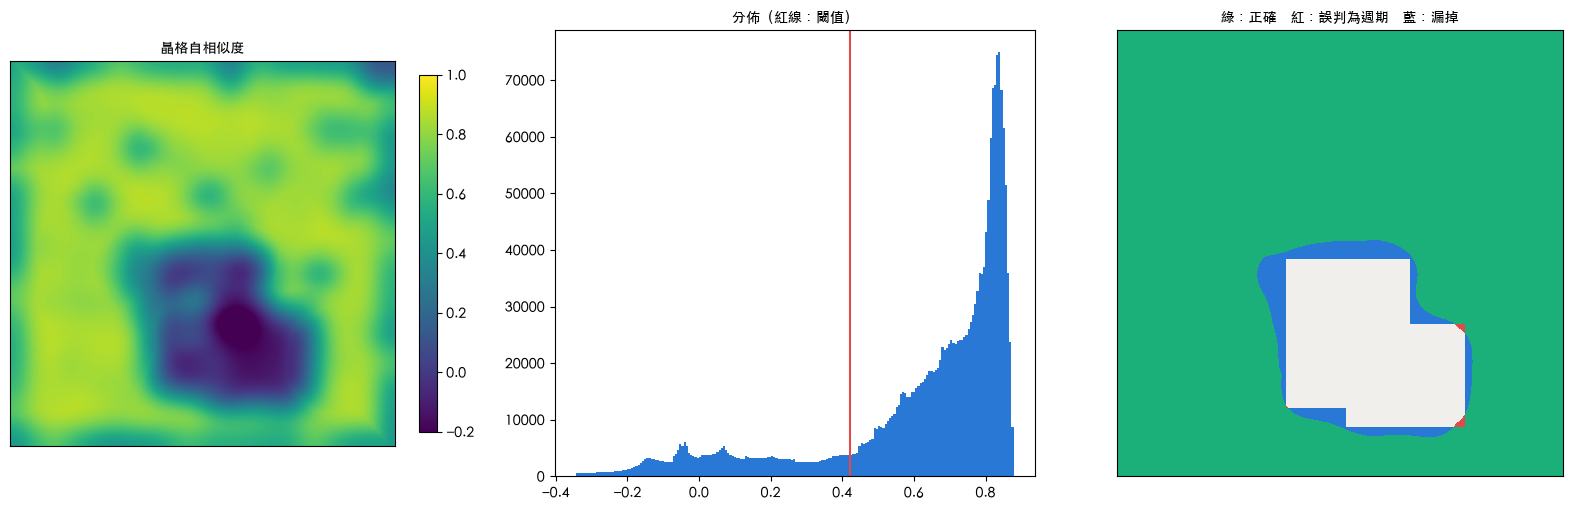

Periodic Region IoU = 0.961，區域數 = 1


In [7]:
matcher = L.LatticeMatcher()                   # 只拿預設參數
selfsim, periodic, regions, inner = L.periodic_regions(hp, fr, sigma, matcher.amp_frac, matcher.min_region_cells)
gt = scene.periodic_mask

fig, ax = plt.subplots(1, 3, figsize=(16, 5.2))
im = ax[0].imshow(selfsim, cmap="viridis", vmin=-0.2, vmax=1); plt.colorbar(im, ax=ax[0], shrink=0.8)
ax[0].set_title("晶格自相似度")
ax[1].hist(selfsim.ravel(), 200, color=BLUE); ax[1].axvline(matcher.amp_frac * np.percentile(selfsim, 90), color=RED)
ax[1].set_title("分佈（紅線：閾值）")
cmp = np.select([periodic & gt, periodic & ~gt, ~periodic & gt], [1, 2, 3], 0)
ax[2].imshow(cmp, cmap=ListedColormap(["#f0efec", GREEN, RED, BLUE]), vmin=0, vmax=3)
ax[2].set_title("綠：正確　紅：誤判為週期　藍：漏掉")
for a in (ax[0], ax[2]):
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()
print(f"Periodic Region IoU = {(periodic & gt).sum() / (periodic | gt).sum():.3f}，區域數 = {regions.max()}")

**試試看**：`occlusion=0.05` 看微粒造成的洞（小的會被補回）；`noise=0.2` 看自相似度整體下降但仍能分開。

## 5. 晶格節點：Newton 迭代

節點 = $q(x)$ 為整數（六角另含半格）的點。定義相位殘差

$$f_k(x) = \operatorname{wrap}\big(2\pi\, g_k\cdot x + \arg H_k(x) - \arg C_k\big) = 2\pi\, h_k\cdot q(x) \bmod 2\pi$$

節點處 $f=0$。因為 $\nabla f_k \approx 2\pi g_k$，Newton 步就是 $\Delta x = -G^{-1} f / 2\pi$（每步限制 0.3 Cell）。

起點：用全域平移 $\delta_0$（$\arg H_k e^{-i\arg C_k}$ 在 Periodic Region 上的圓形平均）把整數格 $q$ 映成像素。因為有 wrap，每個起點都會收斂到**離它最近**的節點，所以起點誤差只要小於半個 Cell 就好。

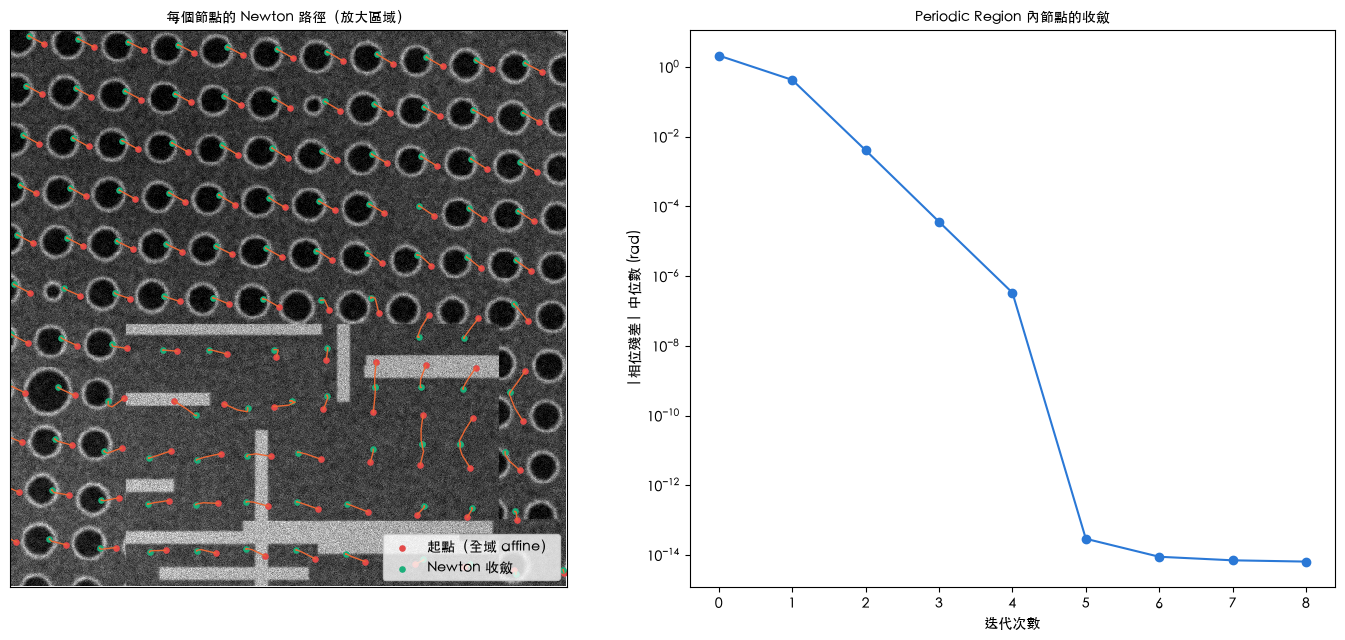

In [8]:
N1, N2, Q = L.node_index_grid(fr, search.shape)
phi = [np.angle(C[k]) for k in fr.hs]          # 先用「諧波不變號」的假設
d0 = L.global_offset(gpa, fr, periodic, phi)
X0, Y0 = np.einsum("ij,jab->iab", fr.Binv, Q - d0[:, None, None])
hist = [(X0, Y0)]
L.newton_nodes(gpa, fr, X0, Y0, phi, history=hist)

res = [np.abs(L.total_phase(gpa, fr, X, Y, phi)).max(0) for X, Y in hist]
inside = (X0 > c0) & (X0 < c0 + 600) & (Y0 > c0) & (Y0 < c0 + 600)

fig, ax = plt.subplots(1, 2, figsize=(14, 6.5))
show_crop(ax[0])
path = np.array([(X[inside], Y[inside]) for X, Y in hist]) - c0     # (iter, 2, n)
for j in range(path.shape[2]):
    ax[0].plot(path[:, 0, j], path[:, 1, j], color=ORANGE, lw=1)
ax[0].scatter(path[0, 0], path[0, 1], s=14, c=RED, label="起點（全域 affine）")
ax[0].scatter(path[-1, 0], path[-1, 1], s=14, c=GREEN, label="Newton 收斂")
ax[0].set_xlim(0, 600); ax[0].set_ylim(600, 0)
ax[0].legend(loc="lower right"); ax[0].set_title("每個節點的 Newton 路徑（放大區域）")
good0 = periodic[np.clip(np.round(hist[-1][1]), 0, H - 1).astype(int), np.clip(np.round(hist[-1][0]), 0, W - 1).astype(int)]
ax[1].plot([np.median(r[good0]) for r in res], "o-", color=BLUE)
ax[1].set_yscale("log"); ax[1].set_xlabel("迭代次數"); ax[1].set_ylabel("|相位殘差| 中位數 (rad)")
ax[1].set_title("Periodic Region 內節點的收斂")
plt.tight_layout(); plt.show()

節點的位置是「Reference 中心在 Search Image 上的對應點」：每個節點都是一個可能的 Instance 中心，而且 **Phase 已經對了**——因為相位是和 $\arg C_k$ 比的。

## 6. 由中心往外擬合 affine，壞節點用鄰近漂移補

尺度只要差 0.4%，跨 40 個 Cell 就累積 0.16 Cell 的誤差。所以從**最靠近影像中心的好節點**開始，半徑 6 → 15 → 全部，每次用 Newton 結果最小平方擬合 affine $x = M n + t$，再重新預測、重新 Newton。

不在 Periodic Region 的節點（微粒、邊界）沒有可靠的相位，用鄰近好節點的漂移（normalized convolution，σ = 2 節點）補位置——這些 Cell 之後會因 ZNCC 低而被標成 Anomalous，而不是消失。

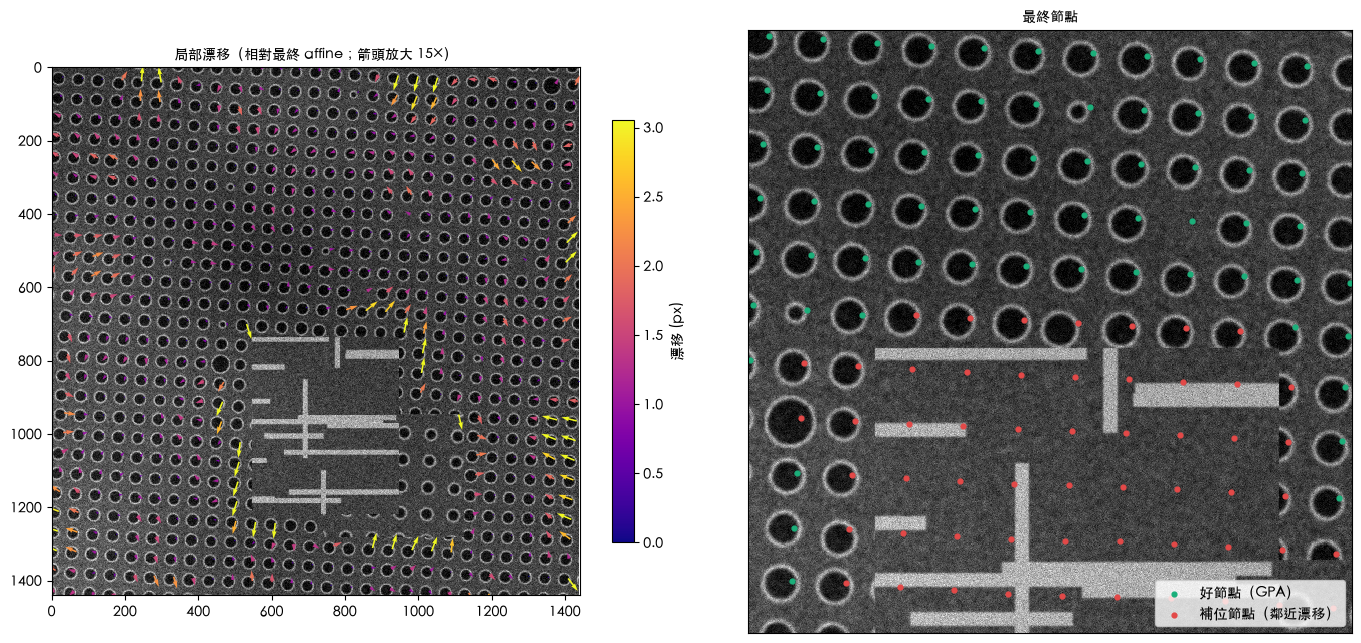

擬合 affine 的每 Cell 位移向量（px）：
[[53.67 -2.93]
 [ 2.91 53.73]]
漂移中位數 1.02 px，最大 8.39 px


In [9]:
nd = L.solve_nodes(gpa, fr, periodic, phi, N1, N2, Q)
good = nd["good"]
drift = np.stack([nd["Xs"] - nd["Xa"], nd["Ys"] - nd["Ya"]])
mag = np.hypot(*drift)

fig, ax = plt.subplots(1, 2, figsize=(14, 6.5))
ax[0].imshow(search, cmap="gray")
# 放大倍率：第 75 百分位的漂移畫成 0.4 Cell；邊界少數大漂移的箭頭截在 0.8 Cell
amp_q = 0.4 * fr.cell_s / max(np.percentile(mag[good], 75), 1e-3)
u, v = drift[0][good] * amp_q, drift[1][good] * amp_q
clip = np.minimum(1, 0.8 * fr.cell_s / (np.hypot(u, v) + 1e-9))
q = ax[0].quiver(nd["Xa"][good], nd["Ya"][good], u * clip, v * clip, mag[good], angles="xy", scale_units="xy",
                 scale=1, cmap="plasma", width=0.003, clim=(0, np.percentile(mag[good], 95)))
plt.colorbar(q, ax=ax[0], shrink=0.7, label="漂移 (px)")
ax[0].set_title(f"局部漂移（相對最終 affine；箭頭放大 {amp_q:.0f}×）")
ax[0].set_xlim(0, W); ax[0].set_ylim(H, 0)
show_crop(ax[1])
for m_, col, lab in [(good, GREEN, "好節點（GPA）"), (~good, RED, "補位節點（鄰近漂移）")]:
    sel = m_ & (nd["Xf"] > c0) & (nd["Xf"] < c0 + 600) & (nd["Yf"] > c0) & (nd["Yf"] < c0 + 600)
    ax[1].scatter(nd["Xf"][sel] - c0, nd["Yf"][sel] - c0, s=12, c=col, label=lab)
ax[1].legend(loc="lower right"); ax[1].set_title("最終節點")
plt.tight_layout(); plt.show()
print(f"擬合 affine 的每 Cell 位移向量（px）：\n{(nd['coef'][:2].T @ fr.Hm).round(2)}")
print(f"漂移中位數 {np.median(mag[good]):.2f} px，最大 {mag[good].max():.2f} px")

注意：節點是「Reference **中心**」的對應點，不是孔的中心。這裡 `HOLE_OFFSET=(0.3, 0.6)`，所以每個節點都落在孔的同一個相對位置——這正是 Phase 對齊的意思。

**試試看**：`elastic=0.15`，漂移場會變大但很平滑；`elastic=0`，剩下的只是雜訊級的漂移。靠近非週期區邊界的少數節點漂移特別大：那裡的相位受邊界污染，之後檢查框時會用內縮的 Periodic Region 把它們排除。

## 7. 極性與諧波符號假設

兩件事會讓步驟 5 的 Phase 錯掉：

1. **對比反轉**：影像整個反過來 → 所有 $C_k$ 變號 → 節點偏半格；模板也要變號
2. **強非線性灰階**（如 gamma 3.5）：影像沒反轉，但某個諧波的係數可能變號

所以試 **諧波符號 4 種 × 模板極性 2 種 = 8 種假設**：每種都解一次節點，在節點上取樣 Cell 模板（1.5 Cell 見方、已套估計幾何）的 ZNCC，取**中位數最高**者。

,諧波符號,模板極性,Cell_ZNCC中位數,選中
0,"(1, 1)",+,0.824,★
1,"(1, 1)",−,-0.071,
2,"(1, -1)",+,0.034,
3,"(1, -1)",−,0.099,
4,"(-1, 1)",+,0.032,
5,"(-1, 1)",−,0.096,
6,"(-1, -1)",+,0.141,
7,"(-1, -1)",−,0.007,


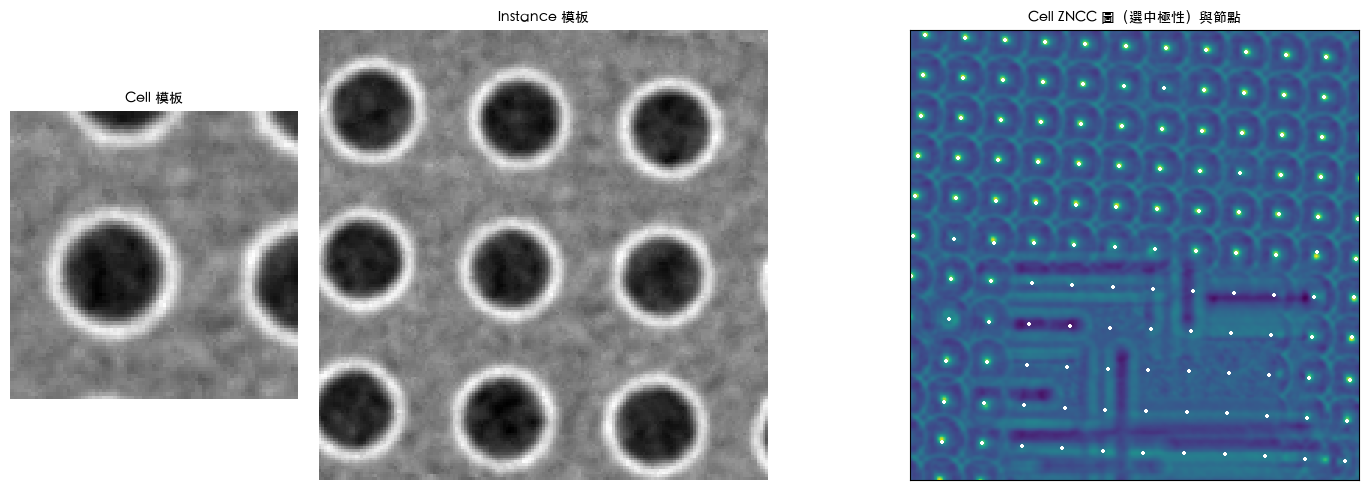

In [10]:
img = search.astype(np.float32)
cell_tmpl, inst_tmpl, cell_map, inst_map = L.templates(img, ref, fr)
hyps = L.score_hypotheses(gpa, fr, C, periodic, cell_map, N1, N2, Q)
best = max(hyps, key=lambda h: h["median"])

df = pd.DataFrame([dict(諧波符號=str(h["flips"]), 模板極性="+" if h["sign"] > 0 else "−",
                        Cell_ZNCC中位數=round(h["median"], 3), 選中="★" if h is best else "") for h in hyps])
display(df)

fig, ax = plt.subplots(1, 3, figsize=(15, 5), gridspec_kw=dict(width_ratios=[1, 1.6, 2.4]))
ax[0].imshow(cell_tmpl, cmap="gray"); ax[0].set_title("Cell 模板")
ax[1].imshow(inst_tmpl, cmap="gray"); ax[1].set_title("Instance 模板")
show_crop(ax[2], best["sign"] * cell_map, cmap="viridis")
ndb = best["nodes"]
sel = (ndb["Xf"] > c0) & (ndb["Xf"] < c0 + 600) & (ndb["Yf"] > c0) & (ndb["Yf"] < c0 + 600)
ax[2].scatter(ndb["Xf"][sel] - c0, ndb["Yf"][sel] - c0, s=10, c="white", marker="+")
ax[2].set_title("Cell ZNCC 圖（選中極性）與節點")
for a in ax[:2]:
    a.axis("off")
plt.tight_layout(); plt.show()

**試試看**：`invert=True` → 選中的會是模板極性「−」；`gamma=3.5` → 選中的可能是 (−1, −1) 或其中一個諧波變號、但模板極性仍為「+」。這就是第一版只試 2 種假設時失敗的情況。

## 8. Instance Grid

一個節點要成為 Instance 候選，必須：

- 它和周圍 8 個 Cell 節點都在**同一塊** Periodic Region
- 3×3 Cell 的框（5×5 取樣點）完整落在影像與內縮的 Periodic Region 內

候選彼此大量重疊（每個 Cell 都可以當中心）。不重疊的排法 = 中心取 $q \bmod 3$ 相同者，共 9 種切法（六角含半格平移共 18 種）。**每塊 Periodic Region 各自取候選數最多的切法**——不需要分數閾值，也不需要 NMS。

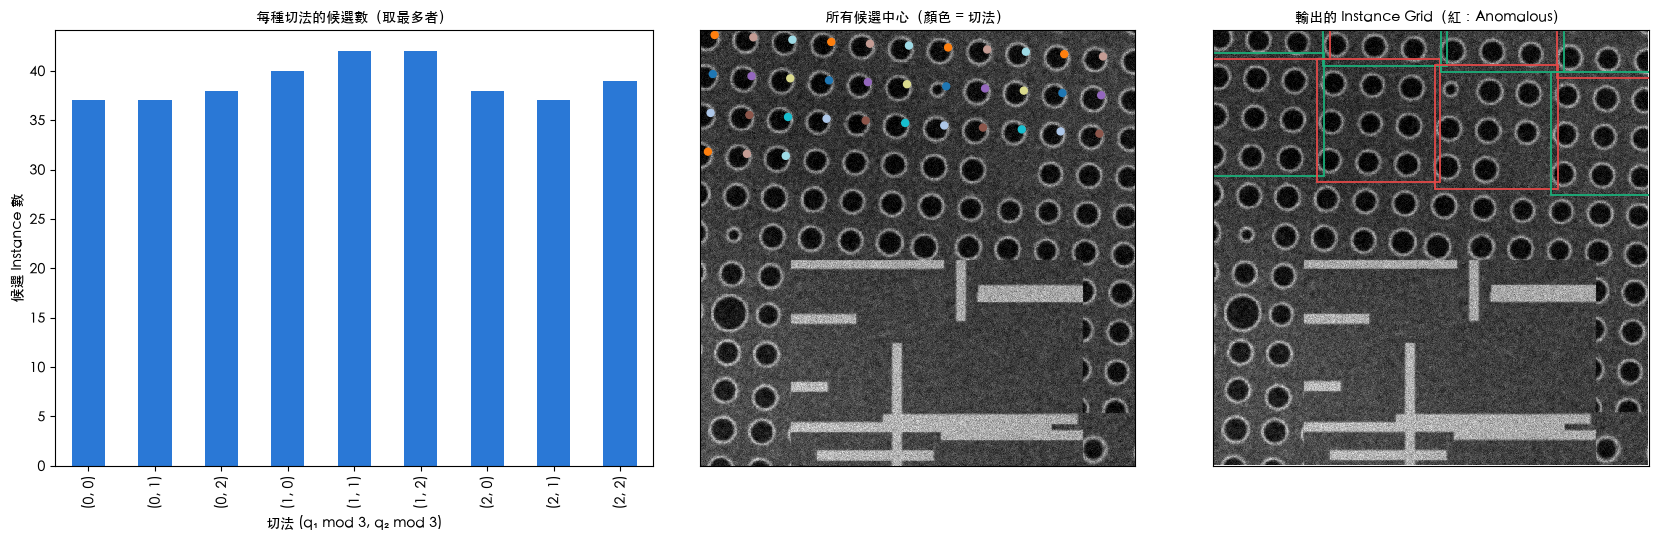

候選 350 個 → 保留 42 個（GT 最多 47 個）


In [11]:
grid = L.instance_grid(fr, ndb, best["cell_score"], regions, inner, N1, N2)
inst = L.finalize(grid, ndb, fr, inst_map, best["sign"], matcher.z_thr)

# 切法以 (q₁ mod 3, q₂ mod 3) 表示；六角陣列的半格平移會出現 .5
label = {c: f"({c // 6 / 2:g}, {c % 6 / 2:g})" for c in np.unique(grid["cls"])}
counts = pd.crosstab(grid["region"], [label[c] for c in grid["cls"]])
fig, ax = plt.subplots(1, 3, figsize=(17, 5.5), gridspec_kw=dict(width_ratios=[1.2, 1, 1]))
counts.T.plot.bar(ax=ax[0], color=[BLUE, ORANGE, GREEN, RED][:len(counts)], legend=len(counts) > 1)
ax[0].set_xlabel("切法 (q₁ mod 3, q₂ mod 3)"); ax[0].set_ylabel("候選 Instance 數"); ax[0].set_title("每種切法的候選數（取最多者）")

cx, cy = ndb["Xf"][grid["a"], grid["b"]], ndb["Yf"][grid["a"], grid["b"]]
sel = (cx > c0) & (cx < c0 + 600) & (cy > c0) & (cy < c0 + 600)
show_crop(ax[1])
ax[1].scatter(cx[sel] - c0, cy[sel] - c0, c=grid["cls"][sel], cmap="tab20", s=25)
ax[1].set_title("所有候選中心（顏色 = 切法）")
show_crop(ax[2])
for (x0, y0, x1, y1), an in zip(inst.boxes, inst.anomalous):
    ax[2].add_patch(plt.Rectangle((x0 - c0, y0 - c0), x1 - x0, y1 - y0, fill=False, lw=1.3, ec=RED if an else GREEN))
ax[2].set_xlim(0, 600); ax[2].set_ylim(600, 0); ax[2].set_title("輸出的 Instance Grid（紅：Anomalous）")
plt.tight_layout(); plt.show()
print(f"候選 {len(grid['a'])} 個 → 保留 {grid['keep'].sum()} 個（GT 最多 {scene.n_max} 個）")

## 9. Anomalous Instance

Instance 分數 = 其 9 個 Cell 的 ZNCC **最小值**：只要有一個 Cell 壞掉就會被拉低，不會像整張 3×3 模板那樣被另外 8 個 Cell 稀釋。再用 robust z-score（中位數、MAD）< −3.5 標記。

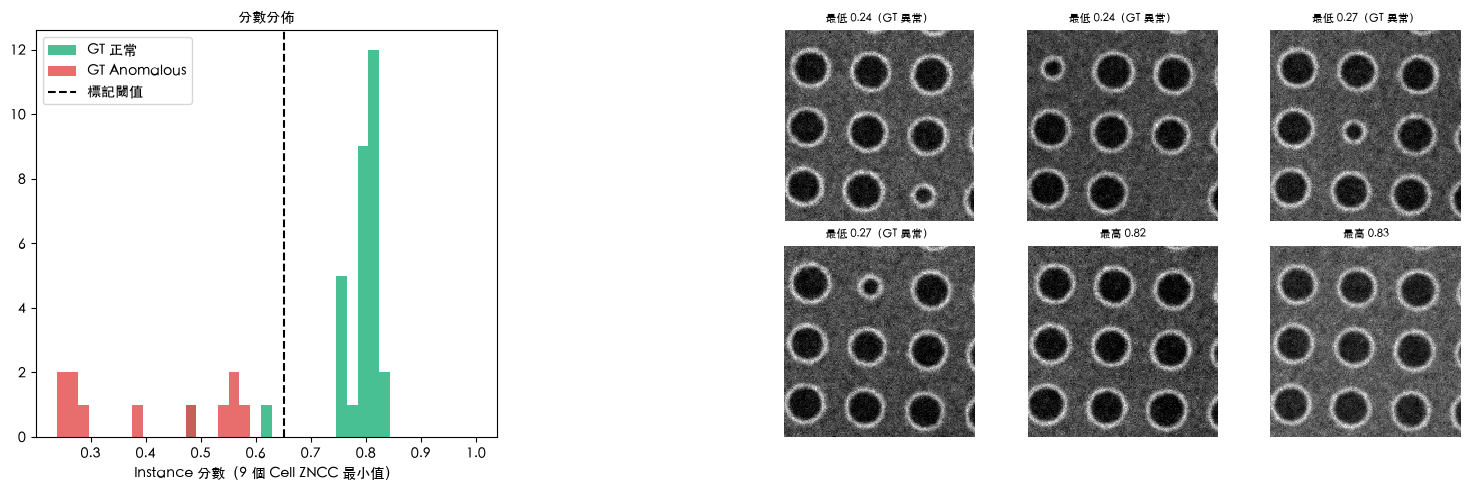

In [12]:
pi, gi = match_instances(inst.centers, scene)
gt_an = np.zeros(len(inst.score), bool); gt_an[pi] = scene.anomalous[gi]
med = np.nanmedian(inst.score); mad = 1.4826 * np.nanmedian(np.abs(inst.score - med))

fig = plt.figure(figsize=(15, 5))
ax = fig.add_subplot(1, 3, 1)
ok = np.isfinite(inst.score)
bins = np.linspace(np.nanmin(inst.score), 1, 40)
ax.hist(inst.score[ok & ~gt_an], bins, color=GREEN, alpha=0.8, label="GT 正常")
ax.hist(inst.score[ok & gt_an], bins, color=RED, alpha=0.8, label="GT Anomalous")
ax.axvline(med - matcher.z_thr * mad, color="k", ls="--", label="標記閾值")
ax.set_xlabel("Instance 分數（9 個 Cell ZNCC 最小值）"); ax.legend(); ax.set_title("分數分佈")

order = np.flatnonzero(ok)[np.argsort(inst.score[ok])]
picks = list(order[:4]) + list(order[-2:])
for j, i in enumerate(picks):
    x0, y0, x1, y1 = np.round(inst.boxes[i]).astype(int)
    a = fig.add_subplot(2, 6, 4 + j % 3 + 6 * (j // 3))
    a.imshow(search[max(0, y0):y1, max(0, x0):x1], cmap="gray")
    a.set_title(f"{'最低' if j < 4 else '最高'} {inst.score[i]:.2f}" + ("（GT 異常）" if gt_an[i] else ""), fontsize=8)
    a.axis("off")
plt.tight_layout(); plt.show()

## 10. 驗證

和 ground truth 比對（預測中心距任一合法 Instance 中心 < 0.25 Cell 即算對；recall 分母是 Instance 最多的切法），並確認這份 notebook 的逐步結果和 `LatticeMatcher().analyze()` 完全相同。

In [13]:
pr = detection_pr(inst.centers, scene)
loc = np.hypot(*(inst.centers[pi] - scene.centers[gi]).T)
print(f"precision {pr['precision']:.3f}　recall {pr['recall']:.3f}（{pr['tp']}/{scene.n_max}）　定位誤差中位數 {np.median(loc):.2f} px")

auto = matcher.analyze(search, ref)["instances"]
assert auto.centers.shape == inst.centers.shape and np.allclose(auto.centers, inst.centers)
print("與 LatticeMatcher().analyze() 結果相同 ✓")

precision 1.000　recall 0.894（42/47）　定位誤差中位數 0.20 px


與 LatticeMatcher().analyze() 結果相同 ✓


## 試試看

改「參數」那格後 *Run All*：

| 設定 | 觀察重點 |
|---|---|
| `invert=True` | 步驟 7 選中模板極性「−」；Template Matching 在這裡 recall 為 0 |
| `gamma=3.5` | 步驟 7 的諧波符號假設；步驟 4 自相似度仍分得開 |
| `occlusion=0.05` | 步驟 4 的洞、步驟 6 的補位節點、步驟 9 的低分 Instance |
| `elastic=0.15` | 步驟 3 相位起伏、步驟 6 漂移場 |
| `LATTICE="hex"` | 步驟 1 選 (1,±1)；步驟 8 有 18 種切法 |
| `PITCH=16` 或 `128` | 小 Cell 節點多、大 Cell 的非週期區只有幾個 Cell 大 |
| `noise=0.2` | Template Matching 的固定閾值在這裡失效；這裡不需要閾值 |

已知弱點（見報告）：大量遮擋時 Periodic Region 被切碎；高 defect 率下 Cell 層級異常分數不如整張模板 ZNCC。